# 6c. Model R(2+1)D + LSTM

Rovnaký LSTM ako v notebooku 5, ale namiesto príznakov jednotlivých snímok z ResNet18
číta postupnosť príznakov z video siete R(2+1)D: klip je rozdelený na 4 úseky po 8 snímok
a každý úsek je opísaný 512 príznakmi (notebook 3) → `(4, 512)` na klip.

Spolu s notebookmi 4, 5 a 6 vzniká porovnanie 2 × 2:

| | SVM | LSTM |
|---|---|---|
| ResNet18 (snímky, ImageNet) | notebook 4 | notebook 5 |
| R(2+1)D (video, Kinetics) | notebook 6 | notebook 6c |

**Trénovanie** (`har/models.py`):
- 20 % filmov z trénovacích dát sa oddelí ako validačné dáta,
- po každej epoche sa zmeria strata na validačných dátach; model ponechá váhy z epochy
  s najnižšou validačnou stratou (**early stopping**),
- 1 vrstva LSTM so 128 neurónmi, dropout 0,5, váhy tried v stratovej funkcii.

Hodnotenie je rovnaké ako v notebooku 4.

In [1]:
import numpy as np
import pandas as pd
import torch

from har.config import INDEX_FILE
from har.evaluation import evaluate_lstm, plot_confusion, plot_history, save_predictions, summary

df = pd.read_csv(INDEX_FILE)
feats = np.load("features_r21d_seq.npy")   # (klipy, 4, 512)
device = "cuda" if torch.cuda.is_available() else "cpu"

## Hodnotenie

In [2]:
pred, (history, best_epoch) = evaluate_lstm(feats, df, device)
save_predictions(pred, "video_lstm")
summary(pred, "R(2+1)D + LSTM")

,presnosť (accuracy),správne eat (recall),správne clap (recall)
R(2+1)D + LSTM,91 % ± 4 %,99 % ± 3 %,86 % ± 8 %


## Priebeh trénovania

Strata na trénovacích a validačných dátach v prvom delení.
Zvislá čiara označuje epochu, ktorej váhy model používa.

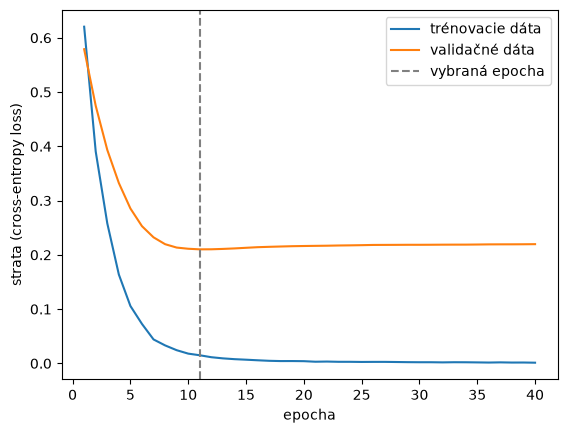

In [3]:
plot_history(history, best_epoch)

## Chyby modelu

Matica zámen (*confusion matrix*) zo všetkých 10 delení. Riadok = skutočná trieda,
stĺpec = predpoveď modelu.
- vľavo: počet testovacích klipov (súčet cez 10 delení, každý klip je v teste viackrát),
- vpravo: % klipov danej skutočnej triedy (súčet v riadku je 100 %).

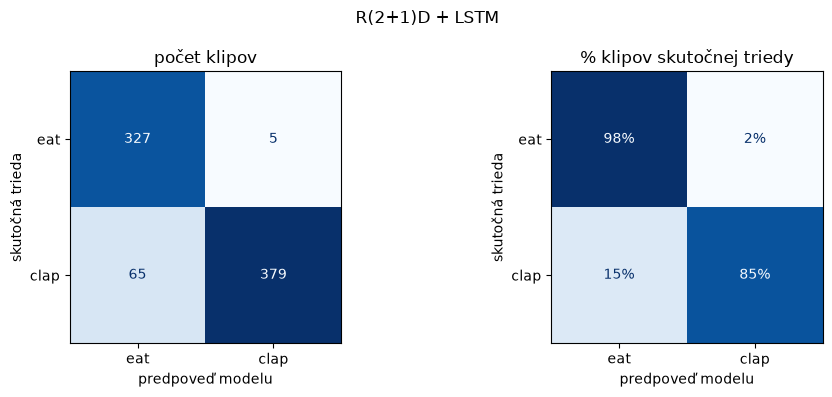

In [4]:
plot_confusion(pred, "R(2+1)D + LSTM")